# **Diabetes Risk Prediction Model**
Diabetes is among the most prevalent chronic diseases in the United States, impacting millions of Americans each year and exerting a significant financial burden on the economy. Diabetes is a serious chronic disease in which individuals lose the ability to effectively regulate levels of glucose in the blood, and can lead to reduced quality of life and life expectancy

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
from matplotlib import pyplot as plt

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv
/kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_binary_health_indicators_BRFSS2015.csv
/kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_012_health_indicators_BRFSS2015.csv


In [2]:
health_indicators = pd.read_csv('/kaggle/input/datasets/alexteboul/diabetes-health-indicators-dataset/diabetes_012_health_indicators_BRFSS2015.csv')
health_indicators.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
health_indicators.isnull().sum()

Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

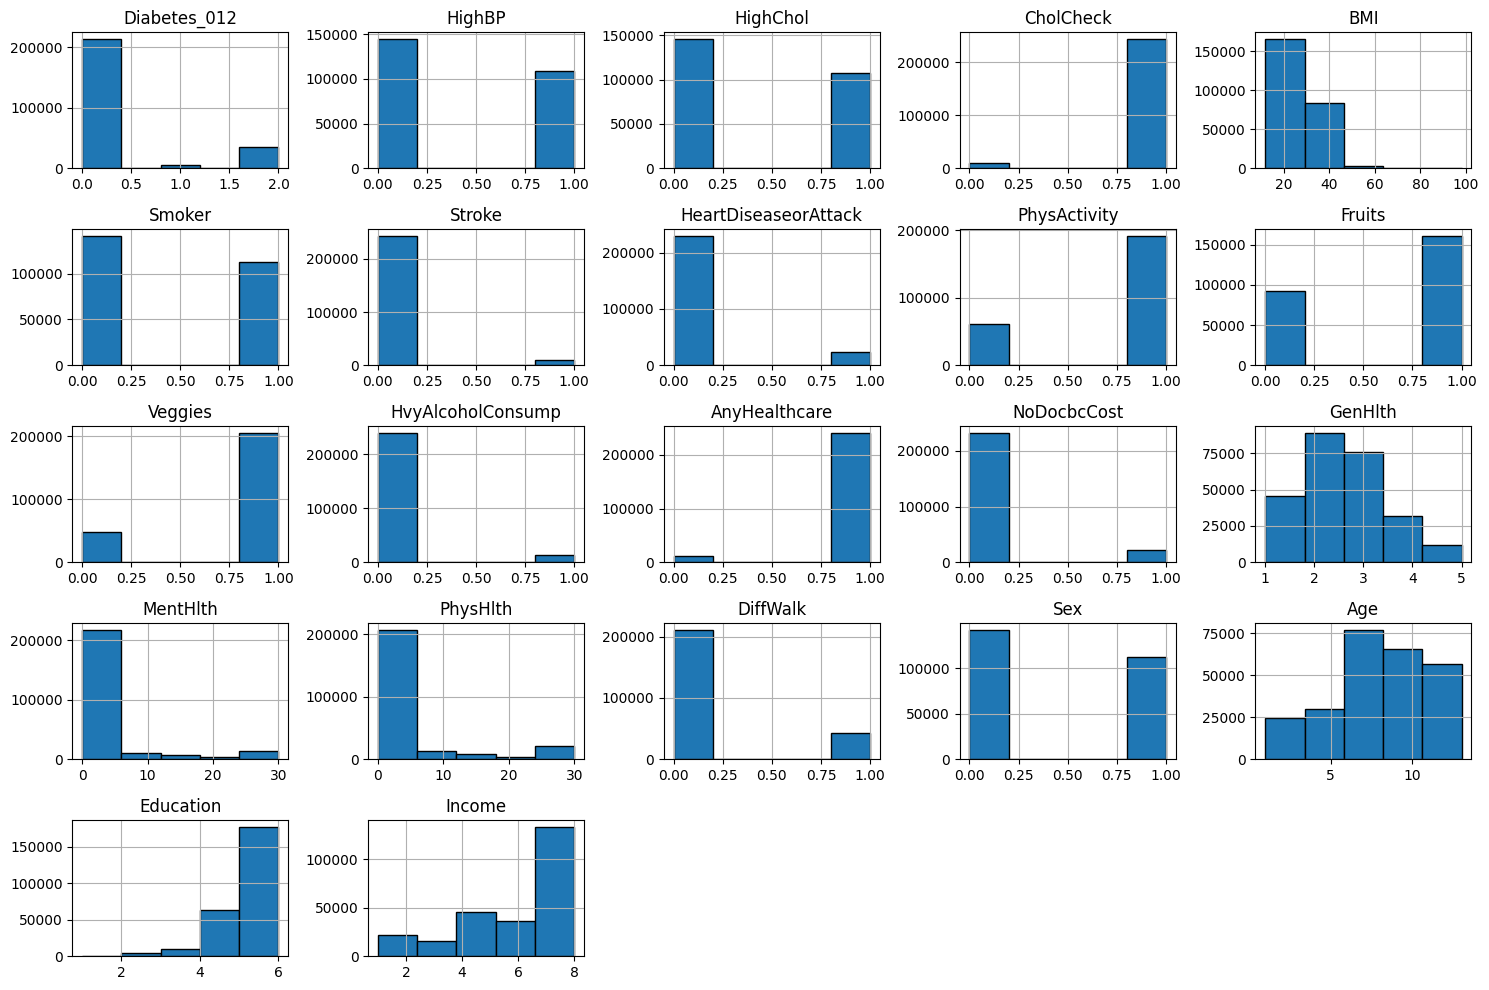

In [4]:
health_indicators.hist(bins=5, figsize=(15, 10), edgecolor='black')
plt.tight_layout()
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features (X) and target (y)
X = health_indicators.drop(columns=['Diabetes_012'])
y = health_indicators['Diabetes_012']

# Define continuous/ordinal columns to scale
num_cols = ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']

# Stratified split to preserve class ratios
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit scaler strictly on training data, then transform both train and test
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

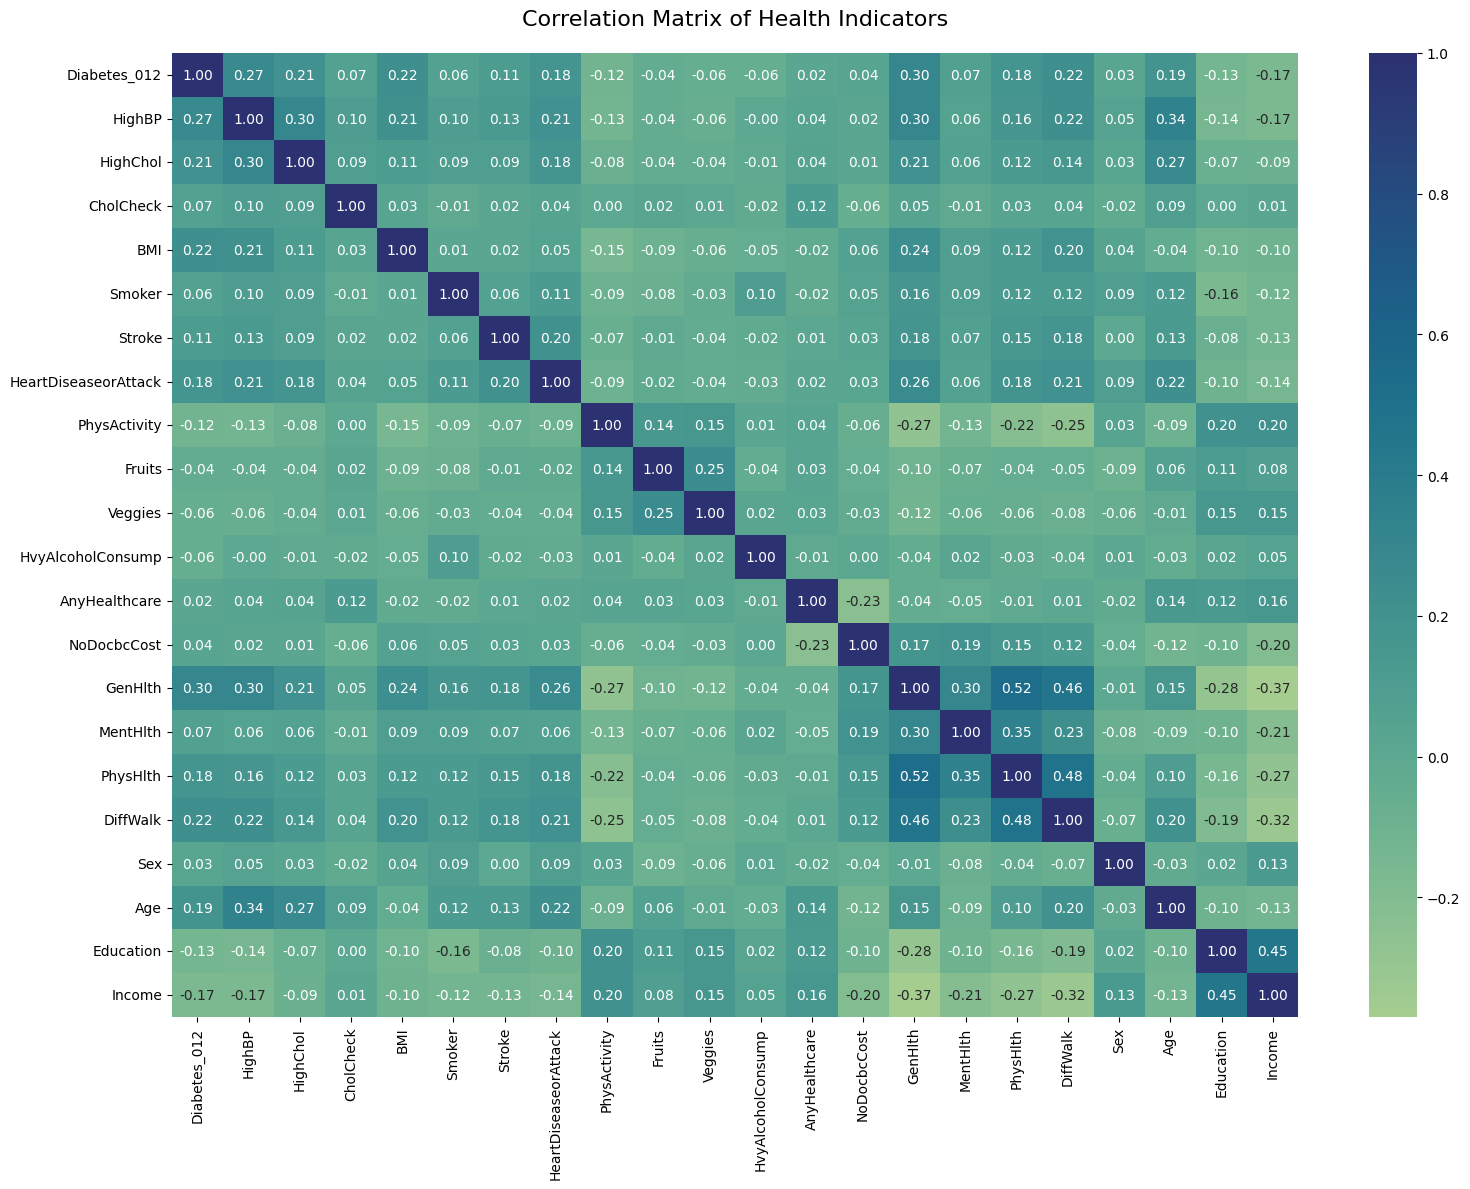

In [6]:
corr = health_indicators.corr()
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr, 
    annot=True, 
    fmt=".2f", 
    cmap="crest"
)

plt.title("Correlation Matrix of Health Indicators", fontsize=16, pad=20)
plt.tight_layout()
plt.show()

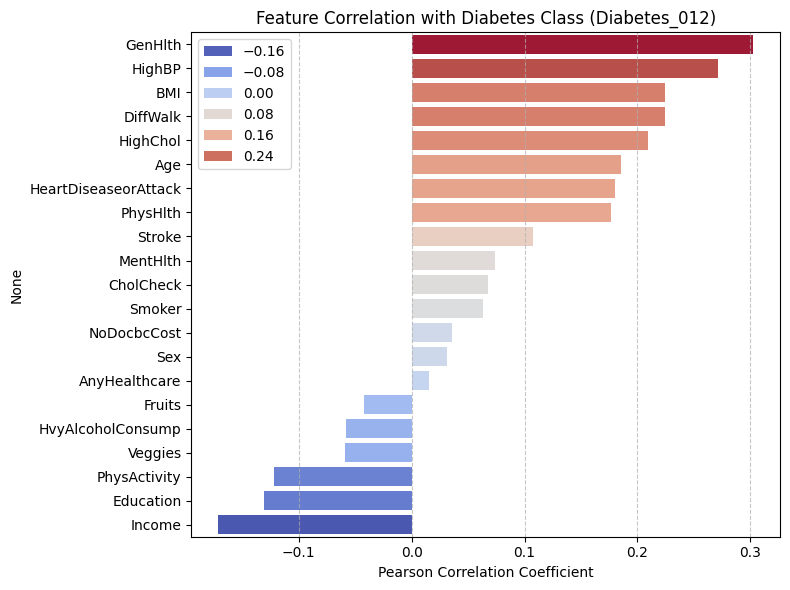

In [7]:
target_corr = corr['Diabetes_012'].drop('Diabetes_012').sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=target_corr.values, y=target_corr.index, hue=target_corr.values, palette="coolwarm")
plt.title("Feature Correlation with Diabetes Class (Diabetes_012)")
plt.xlabel("Pearson Correlation Coefficient")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(
        multi_class='multinomial', 
        solver='lbfgs', 
        class_weight='balanced', 
        max_iter=1000, 
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, 
        class_weight='balanced', 
        random_state=42, 
        n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        objective='multi:softprob',
        num_class=3,
        eval_metric='mlogloss',
        random_state=42,
        n_jobs=-1
    )
}

# Compute sample weights for XGBoost to handle multi-class imbalance
from sklearn.utils.class_weight import compute_sample_weight
sample_weights_train = compute_sample_weight('balanced', y_train)

In [9]:
results = []

for name, model in models.items():
    print(f"\n==================== Training {name} ====================")
    
    # Use scaled features for Logistic Regression; unscaled features work fine for trees
    if name == "Logistic Regression":
        X_tr, X_te = X_train_scaled, X_test_scaled
        model.fit(X_tr, y_train)
    elif name == "XGBoost":
        X_tr, X_te = X_train, X_test
        model.fit(X_tr, y_train, sample_weight=sample_weights_train)
    else:
        X_tr, X_te = X_train, X_test
        model.fit(X_tr, y_train)
        
    # Predictions & Probabilities
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)
    
    # Calculate macro-level metrics
    macro_f1 = f1_score(y_test, y_pred, average='macro')
    auc_score = roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro')
    
    results.append({
        "Model": name,
        "Macro F1-Score": round(macro_f1, 4),
        "Macro ROC-AUC (OvR)": round(auc_score, 4)
    })
    
    # Detailed classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['No Diabetes (0)', 'Prediabetes (1)', 'Diabetes (2)']))

# ---------------------------------------------------------
# 3. Model Benchmark Comparison
# ---------------------------------------------------------

comparison_df = pd.DataFrame(results).sort_values(by="Macro F1-Score", ascending=False)
print("\n================ Baseline Summary Comparison ================")
print(comparison_df.to_string(index=False))


==================== Training Logistic Regression ====================


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(



Classification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.95      0.66      0.78     42741
Prediabetes (1)       0.03      0.33      0.06       926
   Diabetes (2)       0.35      0.58      0.44      7069

       accuracy                           0.65     50736
      macro avg       0.45      0.52      0.43     50736
   weighted avg       0.85      0.65      0.72     50736


==================== Training Random Forest ====================

Classification Report:
                 precision    recall  f1-score   support

No Diabetes (0)       0.86      0.97      0.91     42741
Prediabetes (1)       0.00      0.00      0.00       926
   Diabetes (2)       0.47      0.16      0.24      7069

       accuracy                           0.84     50736
      macro avg       0.44      0.38      0.38     50736
   weighted avg       0.79      0.84      0.80     50736


==================== Training XGBoost ====================

Classification Report

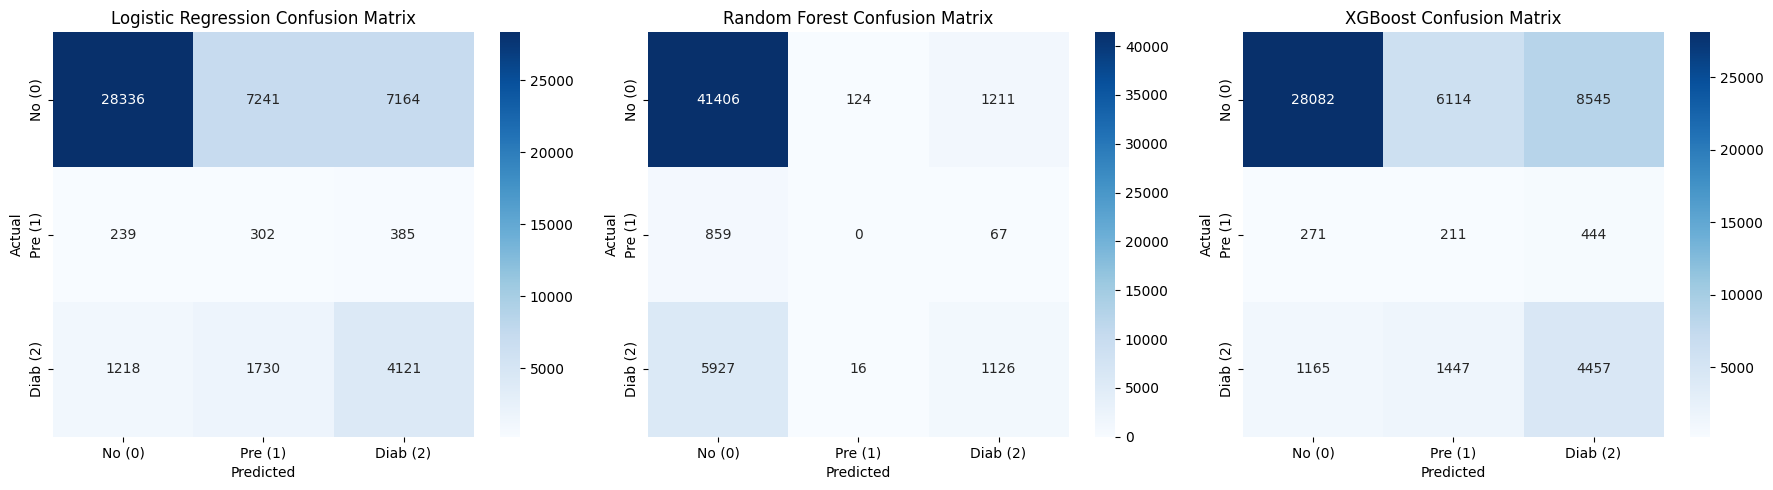

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, models.items()):
    X_te = X_test_scaled if name == "Logistic Regression" else X_test
    y_pred = model.predict(X_te)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['No (0)', 'Pre (1)', 'Diab (2)'],
                yticklabels=['No (0)', 'Pre (1)', 'Diab (2)'])
    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()